Low-frequency gain: 4.53 dB
-3 dB target: 1.53 dB
Estimated -3 dB bandwidth: 9.95 Hz
Phase at -3 dB point: -45.3 deg


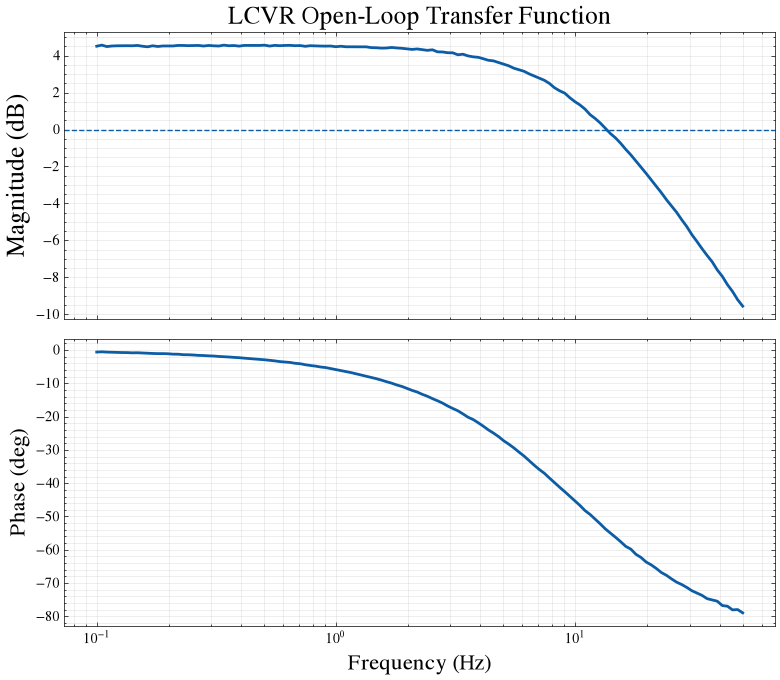

In [38]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots 
plt.style.use(["science", "no-latex"])


# ============================================================
# 1. LOAD MOKU FREQUENCY RESPONSE DATA
# ============================================================

folder = Path(
    "/Users/vib26108/Desktop/Work/PostDoc/laser_RIN"
)

file = folder / "LCVR_OpenLoopTF_20260907_121811_Traces.csv"

data = pd.read_csv(
    file,
    comment="%",
    header=None,
    names=[
        "frequency",
        "magnitude_db",
        "phase_deg",
    ],
)

# Make sure everything is numeric
data = data.apply(pd.to_numeric, errors="coerce").dropna()

frequency = data["frequency"].to_numpy()
magnitude_db = data["magnitude_db"].to_numpy()
phase_deg = data["phase_deg"].to_numpy()


# ============================================================
# 2. PLOT OPEN-LOOP TRANSFER FUNCTION
# ============================================================

fig, (ax_mag, ax_phase) = plt.subplots(
    2,
    1,
    figsize=(8, 7),
    sharex=True,
)

# Magnitude
ax_mag.semilogx(
    frequency,
    magnitude_db,
    linewidth=2,
)

ax_mag.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax_mag.set_ylabel("Magnitude (dB)",fontsize=18)
ax_mag.set_title("LCVR Open-Loop Transfer Function", fontsize=18)
ax_mag.grid(True, which="both", alpha=0.3)


# Phase
ax_phase.semilogx(
    frequency,
    phase_deg,
    linewidth=2,
)

ax_phase.set_xlabel("Frequency (Hz)", fontsize=16)
ax_phase.set_ylabel("Phase (deg)", fontsize=16)
ax_phase.grid(True, which="both", alpha=0.3)

# ============================================================
# 3. ESTIMATE LOW-FREQUENCY GAIN AND -3 dB BANDWIDTH
# ============================================================

# Average the first 10 points to estimate DC / low-frequency gain
low_freq_gain_db = np.mean(magnitude_db[:10])

target_db = low_freq_gain_db - 3

# Find point closest to -3 dB relative to low-frequency gain
idx_3db = np.argmin(np.abs(magnitude_db - target_db))

f_3db = frequency[idx_3db]

print(f"Low-frequency gain: {low_freq_gain_db:.2f} dB")
print(f"-3 dB target: {target_db:.2f} dB")
print(f"Estimated -3 dB bandwidth: {f_3db:.2f} Hz")
print(f"Phase at -3 dB point: {phase_deg[idx_3db]:.1f} deg")

plt.tight_layout()
plt.show()

# Free running RIN

Frequency resolution: 0.953674 Hz
Frequency resolution: 0.953674 Hz


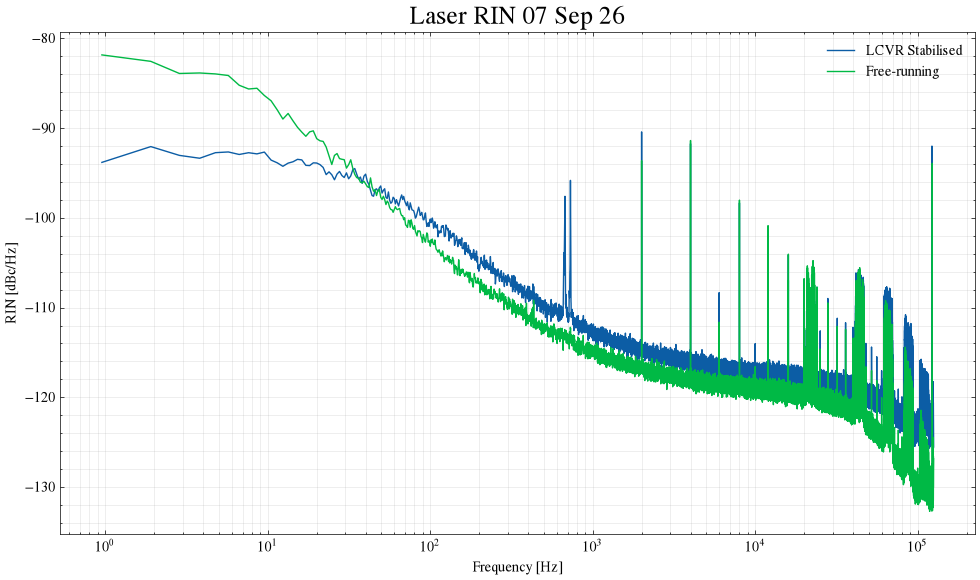

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
import scienceplots 
plt.style.use(["science", "no-latex"])
fs = 250_000
duration = 60  # seconds
number_of_samples = int(fs * duration)
plt.figure(figsize=(10, 6))

voltage = pd.read_csv(
    "/Users/vib26108/Desktop/Work/PostDoc/laser_RIN/MokuDataLoggerSlot2Data_20260907_134100.csv",
    skiprows=11,
    header=None,
    names=["Time", "Voltage"],
    usecols=["Voltage"],
    dtype={"Voltage": np.float32},
    nrows=number_of_samples,
)["Voltage"].to_numpy()

voltage_dc = np.mean(voltage, dtype=np.float64)

f, voltage_psd = welch(
    voltage,
    fs=fs,
    window="hann",
    nperseg=2**18,
    noverlap=2**17,
    nfft=2**18,
    detrend="constant",
    scaling="density",
    average="mean",
)
print(f"Frequency resolution: {f[1] - f[0]:.6g} Hz")
rin_psd = voltage_psd / voltage_dc**2
rin_db = 10 * np.log10(rin_psd)

plt.semilogx(f[1:], rin_db[1:],label="LCVR Stabilised")
plt.xlabel("Frequency [Hz]")
plt.ylabel("RIN [dBc/Hz]")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
voltage = pd.read_csv(
    "/Users/vib26108/Desktop/Work/PostDoc/laser_RIN/MokuDataLoggerSlot2Data_20260907_135237.csv",
    skiprows=11,
    header=None,
    names=["Time", "Voltage"],
    usecols=["Voltage"],
    dtype={"Voltage": np.float32},
    nrows=number_of_samples,
)["Voltage"].to_numpy()

voltage_dc = np.mean(voltage, dtype=np.float64)

f, voltage_psd = welch(
    voltage,
    fs=fs,
    window="hann",
    nperseg=2**18,
    noverlap=2**17,
    nfft=2**18,
    detrend="constant",
    scaling="density",
    average="mean",
)
print(f"Frequency resolution: {f[1] - f[0]:.6g} Hz")
rin_psd = voltage_psd / voltage_dc**2
rin_db = 10 * np.log10(rin_psd)


plt.title("Laser RIN 07 Sep 26", fontsize=18)
plt.semilogx(f[1:], rin_db[1:],label="Free-running")
plt.xlabel("Frequency [Hz]")
plt.ylabel("RIN [dBc/Hz]")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Frequency resolution: 0.953674 Hz
Frequency resolution: 0.953674 Hz


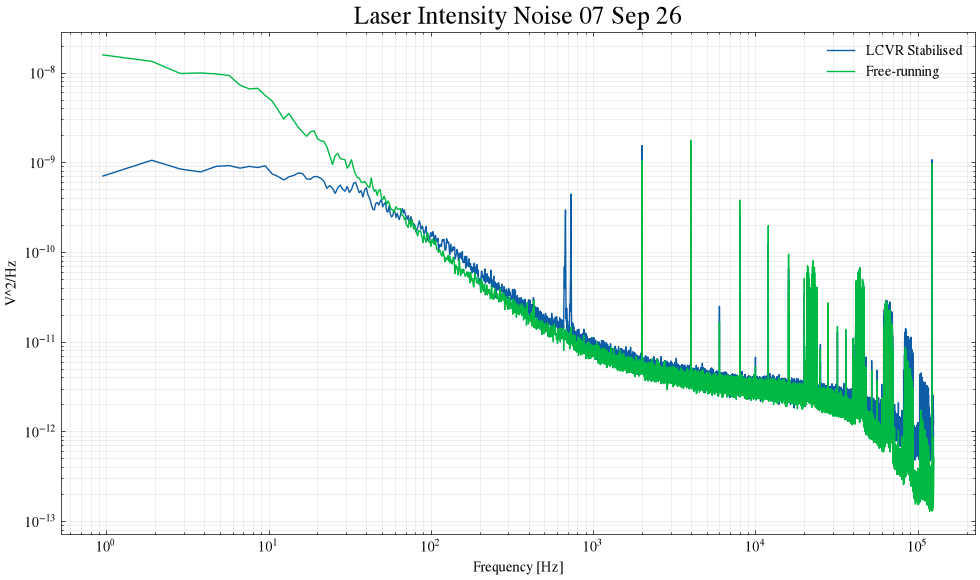

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
import scienceplots 
plt.style.use(["science", "no-latex"])
fs = 250_000
duration = 60  # seconds
number_of_samples = int(fs * duration)
plt.figure(figsize=(10, 6))

voltage = pd.read_csv(
    "/Users/vib26108/Desktop/Work/PostDoc/laser_RIN/MokuDataLoggerSlot2Data_20260907_134100.csv",
    skiprows=11,
    header=None,
    names=["Time", "Voltage"],
    usecols=["Voltage"],
    dtype={"Voltage": np.float32},
    nrows=number_of_samples,
)["Voltage"].to_numpy()

voltage_dc = np.mean(voltage, dtype=np.float64)

f, voltage_psd = welch(
    voltage,
    fs=fs,
    window="hann",
    nperseg=2**18,
    noverlap=2**17,
    nfft=2**18,
    detrend="constant",
    scaling="density",
    average="mean",
)
print(f"Frequency resolution: {f[1] - f[0]:.6g} Hz")
rin_psd = voltage_psd / voltage_dc**2
rin_db = 10 * np.log10(rin_psd)

plt.loglog(f[1:], voltage_psd[1:],label="LCVR Stabilised")
plt.xlabel("Frequency [Hz]")
plt.ylabel("RIN [dBc/Hz]")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
voltage = pd.read_csv(
    "/Users/vib26108/Desktop/Work/PostDoc/laser_RIN/MokuDataLoggerSlot2Data_20260907_135237.csv",
    skiprows=11,
    header=None,
    names=["Time", "Voltage"],
    usecols=["Voltage"],
    dtype={"Voltage": np.float32},
    nrows=number_of_samples,
)["Voltage"].to_numpy()

voltage_dc = np.mean(voltage, dtype=np.float64)

f, voltage_psd = welch(
    voltage,
    fs=fs,
    window="hann",
    nperseg=2**18,
    noverlap=2**17,
    nfft=2**18,
    detrend="constant",
    scaling="density",
    average="mean",
)
print(f"Frequency resolution: {f[1] - f[0]:.6g} Hz")
rin_psd = voltage_psd / voltage_dc**2
rin_db = 10 * np.log10(rin_psd)


plt.title("Laser Intensity Noise 07 Sep 26", fontsize=18)
plt.loglog(f[1:], voltage_psd[1:],label="Free-running")
plt.xlabel("Frequency [Hz]")
plt.ylabel("V^2/Hz")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



In [42]:
import numpy as np

attenuation_db = 14
attenuation_correction = 10**(attenuation_db / 20)

# Undo the 14 dB attenuation
voltage_detector = voltage.astype(np.float64) * attenuation_correction

voltage_dc = np.mean(voltage_detector)
voltage_noise = voltage_detector - voltage_dc
voltage_rms = np.sqrt(np.mean(voltage_noise**2))

# Detector parameters
responsivity = 0.48 # A/W: replace with value at your wavelength
gain_db = 0         # replace with PDA36A2 gain setting

gain_high_z = {
    0: 1.51e3,
    10: 4.75e3,
    20: 1.50e4,
    30: 4.75e4,
    40: 1.51e5,
    50: 4.75e5,
    60: 1.50e6,
    70: 4.75e6,
}

gain_50ohm = {
    0: 0.75e3,
    10: 2.38e3,
    20: 0.75e4,
    30: 2.38e4,
    40: 0.75e5,
    50: 2.38e5,
    60: 0.75e6,
    70: 2.38e6,
}

# Choose this based on the Moku input termination
input_is_50ohm = False

gain = (
    gain_50ohm[gain_db]
    if input_is_50ohm
    else gain_high_z[gain_db]
)

volts_per_watt = responsivity * gain

mean_optical_power = voltage_dc / volts_per_watt
power_noise_rms = voltage_rms / volts_per_watt

print(f"Attenuation correction: {attenuation_correction:.4f}×")
print(f"Detector DC voltage:    {voltage_dc:.6g} V")
print(f"Voltage noise RMS:      {voltage_rms:.6g} V RMS")
print(f"Mean optical power:     {mean_optical_power:.6g} W")
print(f"Mean optical power:     {mean_optical_power * 1e3:.6g} mW")
print(f"Power noise RMS:        {power_noise_rms:.6g} W RMS")
print(f"Power noise RMS:        {power_noise_rms * 1e6:.6g} µW RMS")


from scipy.integrate import trapezoid

f_min = 10
f_max = 100_000
band = (f >= f_min) & (f <= f_max)

# voltage_psd is based on the voltage stored in the CSV
voltage_psd_detector = voltage_psd * 10**(attenuation_db / 10)

power_psd = voltage_psd_detector / volts_per_watt**2

power_rms_band = np.sqrt(
    trapezoid(power_psd[band], f[band])
)

print(
    f"Optical-power RMS noise ({f_min:g}–{f_max:g} Hz): "
    f"{power_rms_band * 1e6:.6g} µW RMS"
)

Attenuation correction: 5.0119×
Detector DC voltage:    6.51657 V
Voltage noise RMS:      0.00360721 V RMS
Mean optical power:     0.00899085 W
Mean optical power:     8.99085 mW
Power noise RMS:        4.97684e-06 W RMS
Power noise RMS:        4.97684 µW RMS
Optical-power RMS noise (10–100000 Hz): 4.35684 µW RMS
